# Machine Learning Mini Project — Phase 1

## Movie Recommendation System Using Machine Learning
### A Historical Hotstar Catalogue Study

### **Student 1:** Adithya Nayak — **Register number:** 251090700070

### **Student 2:** Shrinidhi Acharya — **Register number:** 251090700077

**Phase 1:** Problem definition, dataset analysis, exploratory data analysis and model planning.


## 1. Introduction

Streaming services contain many movies. Users may find it difficult to choose a movie they will enjoy. A recommendation system helps by suggesting movies based on their interests and preferences.
Our project will study movie descriptions, genres and user ratings. The final system will recommend movies similar to a user's favourite movies and explore recommendations based on users with similar preferences.

## 2. Problem Statement
Searching a large catalogue manually takes time. Showing the same popular movies to everyone may ignore individual preferences.

This project aims to rank suitable, unseen movies for a user. We use a historical Hotstar catalogue for movie information and MovieLens ratings for a limited subset of matching movies. Movies without matching ratings can still receive content-based recommendations.

## 3. Objectives

1. Identify suitable movie metadata and user-rating datasets.
2. Check missing values, duplicate records, feature types and dataset coverage.
3. Study genres, age ratings, release years, running times and rating patterns.
4. Design preprocessing and an evaluation plan that avoids using test ratings during training.
5. Shortlist six approaches, including two ensemble models, for investigation in the final phase.
6. Build a final system that recommends movies and gives a simple reason for each suggestion.

Model training, performance comparison and the recommendation interface are planned for the final project.

## 4. Dataset Description

| Dataset | Purpose | Main fields |
|---|---|---|
| Historical public Hotstar catalogue | Movie information and content features | `hotstar_id`, `title`, `description`, `genre`, `year`, `age_rating`, `running_time`, `type`, `seasons`, `episodes` |
| MovieLens latest-small: movies | Match movie titles and release years | `movieId`, `title`, `genres` |
| MovieLens latest-small: ratings | User preferences for matched movies | `userId`, `movieId`, `rating`, `timestamp` |

Each Hotstar row describes a movie or TV show; only movies are used for this project. Each MovieLens rating row describes one user's rating of one movie. Ratings range from 0.5 to 5.

**Sources:** [Hotstar CSV repository](https://github.com/SumitMakariye/Hotstar-Data-Analysis-Using-Python) and [GroupLens MovieLens latest-small](https://grouplens.org/datasets/movielens/latest/). Source licences and the MovieLens README are included in `data/`.

The datasets have different identifiers. Matching requires title and release year, followed by checking possible identity mistakes. The catalogue has no actual Hotstar user histories, no language column and no live streaming-availability information.

## 5. Libraries Used

- **Pandas:** Reading and analysing tables.
- **NumPy:** Numerical calculations.
- **Matplotlib:** Graphs and charts.
- **Pathlib, re and unicodedata:** File paths and title normalization.

In [1]:
import importlib.util
import subprocess
import sys

packages = {'pandas': 'pandas>=2,<3', 'numpy': 'numpy>=1.24,<3',
            'matplotlib': 'matplotlib>=3.7,<4', 'IPython': 'ipython>=8'}
missing = [spec for name, spec in packages.items()
           if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
print('Required libraries are available.')

from pathlib import Path
import html
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Set PROJECT_DIR only if the project is stored elsewhere.
PROJECT_DIR = None  # Path to the folder containing the shared data directory.
roots = ([Path(PROJECT_DIR).expanduser()] if PROJECT_DIR is not None else
         [Path.cwd(), Path.cwd().parent, Path.cwd() / 'Movie_Recommendation_Phase3'])
required_files = ['hotstar.csv', 'ml-latest-small/movies.csv', 'ml-latest-small/ratings.csv']
PROJECT_ROOT = next((p.resolve() for p in roots
                     if all((p / 'data' / f).is_file() for f in required_files)), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Keep the shared data folder with the project, or set PROJECT_DIR above.')
DATA = PROJECT_ROOT / 'data'
OUTPUT = PROJECT_ROOT / 'phase1_outputs'
OUTPUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_colwidth', 90)
print('Data folder:', DATA)
hotstar_raw = pd.read_csv(DATA / 'hotstar.csv', dtype={'hotstar_id': str})
ml_movies = pd.read_csv(DATA / 'ml-latest-small/movies.csv')
ratings = pd.read_csv(DATA / 'ml-latest-small/ratings.csv')

movies = hotstar_raw.loc[hotstar_raw['type'].astype(str).str.lower().eq('movie')].copy()
movie_rows_before = len(movies)
movies = movies.dropna(subset=['hotstar_id', 'title'])
for col in ['title', 'description', 'genre', 'age_rating']:
    movies[col] = movies[col].fillna('').astype(str).str.strip()
# Decode HTML entities in catalogue titles before cleaning and matching.
movies['title'] = movies['title'].map(html.unescape)
movies = movies.loc[movies.title.ne('')].drop_duplicates('hotstar_id').copy()
movies['_t'] = movies.title.str.lower()
movies = (movies.sort_values('hotstar_id')
                .drop_duplicates(['_t', 'year', 'description'])
                .drop(columns='_t').reset_index(drop=True))
print('Movies after removing duplicate listings:', len(movies))
assert len(movies) == 4557, 'Unexpected catalogue snapshot after deduplication.'
for col in ['year', 'running_time']:
    movies[col] = pd.to_numeric(movies[col], errors='coerce')
invalid_runtime = movies.running_time.le(0).sum()
movies.loc[movies.running_time.le(0), 'running_time'] = np.nan
movies['description_words'] = movies.description.str.split().str.len()

print('Setup complete: data loaded and movies prepared.')


Required libraries are available.


Data folder: D:\3MIT\ML PROJECT\Movie_Recommendation_Phase3\data
Movies after removing duplicate listings: 4557
Setup complete: data loaded and movies prepared.


**Dataset location.**

In [2]:
print('Data folder:', DATA)


Data folder: D:\3MIT\ML PROJECT\Movie_Recommendation_Phase3\data


## 6. Dataset Description and Metadata

**Reading data.** The original tables are kept so that cleaning decisions can be checked.

In [3]:
metadata = pd.DataFrame([
    {'Dataset': 'Hotstar catalogue', 'Rows': len(hotstar_raw), 'Columns': hotstar_raw.shape[1]},
    {'Dataset': 'MovieLens movies', 'Rows': len(ml_movies), 'Columns': ml_movies.shape[1]},
    {'Dataset': 'MovieLens ratings', 'Rows': len(ratings), 'Columns': ratings.shape[1]}
])
display(metadata)
for name, table in [('Hotstar', hotstar_raw), ('MovieLens movies', ml_movies),
                    ('MovieLens ratings', ratings)]:
    print('\n', name, 'sample and column information')
    display(table.head())
    display(pd.DataFrame({'Data type': table.dtypes.astype(str),
                          'Non-null rows': table.notna().sum(),
                          'Unique values': table.nunique()}))
print('MovieLens users:', ratings.userId.nunique())
display(hotstar_raw.describe(include='all').T)

,Dataset,Rows,Columns
0,Hotstar catalogue,6874,10
1,MovieLens movies,9742,3
2,MovieLens ratings,100836,4



 Hotstar sample and column information


,hotstar_id,title,description,genre,year,age_rating,running_time,seasons,episodes,type
0,1000087439,Sambha - Aajcha Chawa,A young man sets off on a mission to clean up the society from corruption and other ev...,Action,2012,U/A 16+,141.0,NaN,NaN,movie
1,1260023113,Cars Toon: Mater And The Ghostlight,Mater is haunted by a mysterious blue light that teaches him not to play pranks on the...,Animation,2006,U,7.0,NaN,NaN,movie
2,1260103188,Kanmani Rambo Khatija,"Unlucky since birth, Rambo finds hope when he falls in love with Kanmani and Khatija. ...",Romance,2022,U/A 16+,157.0,NaN,NaN,movie
3,1260126754,Butterfly,"While trying to rescue her sister's kids from kidnappers, Geetha excavates shocking se...",Thriller,2022,U/A 16+,136.0,NaN,NaN,movie
4,1260018228,Sister Act,"Rene, a lounge singer, decides to stay at a Christian convent where she changes the dy...",Comedy,1992,U/A 7+,100.0,NaN,NaN,movie


,Data type,Non-null rows,Unique values
hotstar_id,object,6874,6874
title,object,6874,6677
description,object,6874,6815
genre,object,6874,37
year,int64,6874,78
age_rating,object,6874,6
running_time,float64,4568,187
seasons,float64,2306,40
episodes,float64,2306,495
type,object,6874,2



 MovieLens movies sample and column information


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


... (2 outputs left out)

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,Data type,Non-null rows,Unique values
userId,int64,100836,610
movieId,int64,100836,9724
rating,float64,100836,10
timestamp,int64,100836,85043


MovieLens users: 610


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotstar_id,6874,6874,1000087439,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,6874,6677,Rubaru Roshni,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,6874,6815,"Unlucky since birth, Rambo finds hope when he falls in love with Kanmani and Khatija. ...",4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genre,6874,37,Drama,2043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,6874.0,NaN,NaN,NaN,2011.71865,11.936894,1928.0,2009.0,2016.0,2019.0,2023.0
age_rating,6874,6,U/A 13+,2980,NaN,NaN,NaN,NaN,NaN,NaN,NaN
running_time,4568.0,NaN,NaN,NaN,98.746716,49.411142,1.0,70.0,116.0,135.0,229.0
seasons,2306.0,NaN,NaN,NaN,2.661752,4.942716,1.0,1.0,1.0,2.0,73.0
episodes,2306.0,NaN,NaN,NaN,127.366869,258.138186,1.0,6.0,22.0,130.75,3973.0
type,6874,2,movie,4568,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 7. Data Quality Analysis

**Checking missing values and duplicates.** Missing `seasons` or `episodes` values in movie rows are expected: these fields describe TV shows. A shared title does not necessarily mean the same movie.

In [4]:
quality_rows = []
for name, table in [('Hotstar', hotstar_raw), ('MovieLens movies', ml_movies),
                    ('MovieLens ratings', ratings)]:
    print('\nMissing values:', name)
    display(table.isna().sum().to_frame('Missing rows'))
    quality_rows.append({'Dataset': name, 'Duplicate full rows': int(table.duplicated().sum())})
display(pd.DataFrame(quality_rows))
print('Repeated catalogue IDs:', hotstar_raw.hotstar_id.duplicated().sum())
print('Repeated MovieLens IDs:', ml_movies.movieId.duplicated().sum())
print('Repeated user/movie pairs:', ratings.duplicated(['userId', 'movieId']).sum())
print('Ratings outside 0.5 to 5:', (~ratings.rating.between(0.5, 5)).sum())
print('Ratings with unknown movie IDs:', (~ratings.movieId.isin(ml_movies.movieId)).sum())
display(hotstar_raw['type'].value_counts(dropna=False).to_frame('Records'))


Missing values: Hotstar


,Missing rows
hotstar_id,0
title,0
description,0
genre,0
year,0
age_rating,0
running_time,2306
seasons,4568
episodes,4568
type,0



Missing values: MovieLens movies


,Missing rows
movieId,0
title,0
genres,0



Missing values: MovieLens ratings


,Missing rows
userId,0
movieId,0
rating,0
timestamp,0


,Dataset,Duplicate full rows
0,Hotstar,0
1,MovieLens movies,0
2,MovieLens ratings,0


Repeated catalogue IDs: 0
Repeated MovieLens IDs: 0
Repeated user/movie pairs: 0
Ratings outside 0.5 to 5: 0
Ratings with unknown movie IDs: 0


,Records
type,
movie,4568
tv,2306


**Preparing a movie-only table for EDA.** Remove missing identifiers/titles and repeated identifiers; keep movies with missing descriptions for investigation. Convert year and runtime to numbers. Zero or negative runtime is treated as missing in the analysis. No outlier removal is performed.

In [5]:
print('Original movie rows:', movie_rows_before)
print('Movies retained:', len(movies))
print('Zero/negative running times marked missing:', invalid_runtime)
print('Empty descriptions:', movies.description.eq('').sum())
print('Empty genres:', movies.genre.eq('').sum())
display(movies[['hotstar_id', 'title', 'genre', 'year', 'running_time']].head())

Original movie rows: 4568
Movies retained: 4557
Zero/negative running times marked missing: 0
Empty descriptions: 0
Empty genres: 0


,hotstar_id,title,genre,year,running_time
0,1000001027,Fukrey,Comedy,2013,135.0
1,1000001029,Dabangg 2,Action,2012,116.0
2,1000001354,Bhaag Milkha Bhaag,Biopic,2013,178.0
3,1000001356,Force,Action,2011,132.0
4,1000002766,Stanley Ka Dabba,Family,2011,91.0


## 8. Exploratory Data Analysis

### 8.1 Movie Genre Distribution

**Counting movies in each genre.** Frequent genres may dominate recommendations. Coverage across different genres will be considered in the final phase.

,Movies
genre,
Drama,1538
Action,553
Comedy,526
Romance,492
Thriller,308
Animation,238
Family,154
Documentary,134
Horror,101


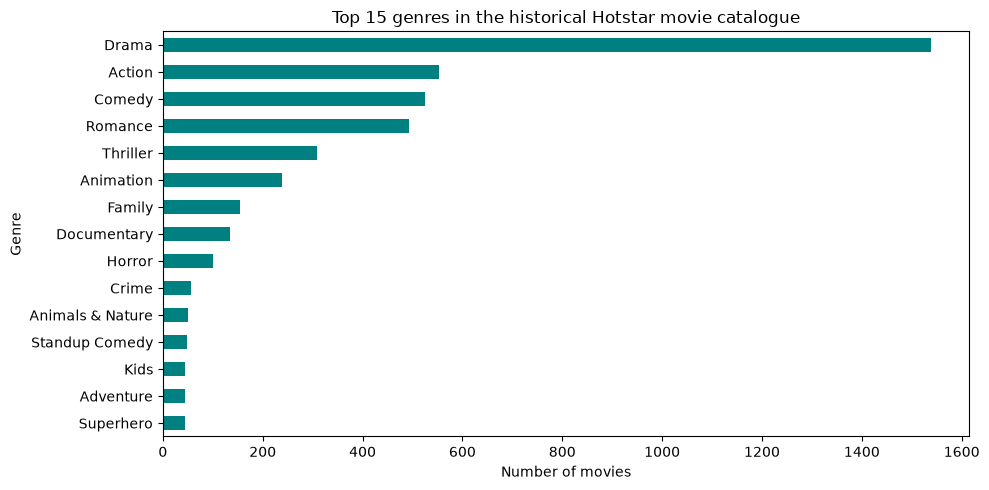

In [6]:
genre_counts = movies.genre.replace('', 'Unknown').value_counts()
display(genre_counts.rename('Movies').to_frame())
fig, ax = plt.subplots(figsize=(10, 5))
genre_counts.head(15).sort_values().plot.barh(ax=ax, color='teal')
ax.set(title='Top 15 genres in the historical Hotstar movie catalogue', xlabel='Number of movies', ylabel='Genre')
plt.tight_layout()
plt.show()

### 8.2 Categorical Feature Analysis

**Checking age-rating labels.** These are catalogue categories, not user preference ratings. A future filter can use them, but they do not by themselves guarantee suitability for a particular viewer.

,Movies
age_rating,
U/A 13+,1822
U/A 16+,970
U,867
U/A 7+,720
A,178


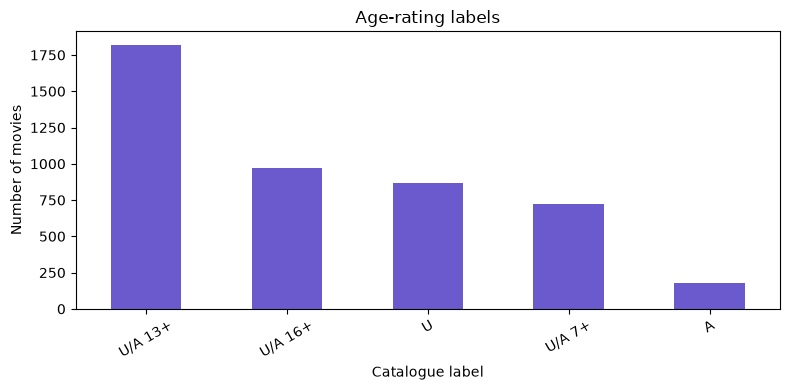

In [7]:
age_counts = movies.age_rating.replace('', 'Unknown').value_counts()
display(age_counts.rename('Movies').to_frame())
fig, ax = plt.subplots(figsize=(8, 4))
age_counts.plot.bar(ax=ax, color='slateblue')
ax.set(title='Age-rating labels', xlabel='Catalogue label', ylabel='Number of movies')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### 8.3 Numerical Feature Analysis

**Studying release years, running times and description lengths.** Identifiers are excluded because their numeric values have no meaningful size or distance.

,count,mean,std,min,25%,50%,75%,max
year,4557.0,2008.691244,13.269101,1928.0,2005.0,2012.0,2018.0,2023.0
running_time,4557.0,98.624314,49.397349,1.0,70.0,116.0,135.0,229.0
description_words,4557.0,25.011630,5.232991,9.0,23.0,25.0,27.0,114.0


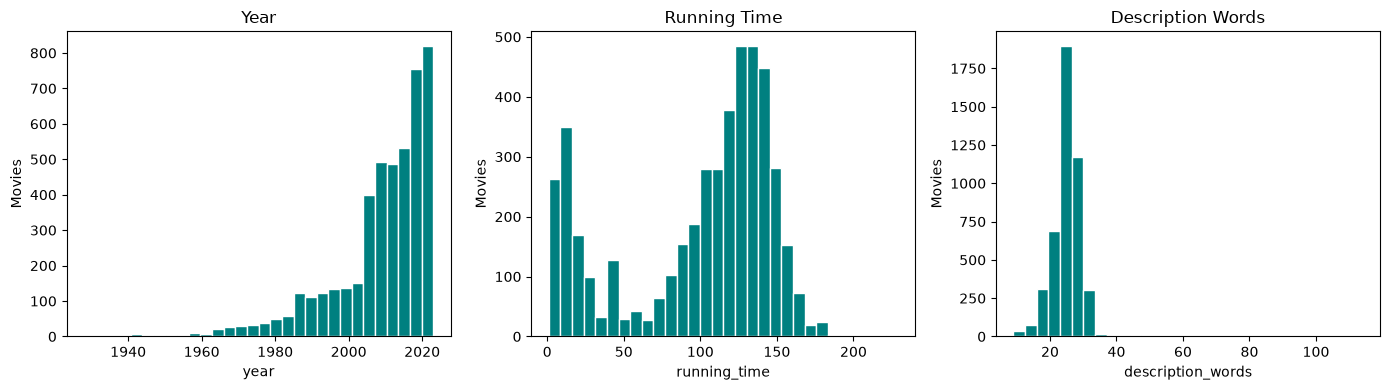

In [8]:
numeric_features = ['year', 'running_time', 'description_words']
display(movies[numeric_features].describe().T)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for col, ax in zip(numeric_features, axes):
    movies[col].dropna().plot.hist(bins=30, ax=ax, color='teal', edgecolor='white')
    ax.set(title=col.replace('_', ' ').title(), xlabel=col, ylabel='Movies')
plt.tight_layout()
plt.show()

### 8.4 Outlier Analysis

**Finding unusual numeric values using the IQR method.** IQR = Q3 − Q1. Values outside Q1 − 1.5 × IQR to Q3 + 1.5 × IQR are flagged. Short films, older movies and long descriptions may be valid, so flagged records are not automatically removed.

In [9]:
outlier_rows = []
for col in numeric_features:
    values = movies[col].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({'Feature': col, 'Lower limit': lower,
                         'Upper limit': upper,
                         'Flagged records': int(((values < lower) | (values > upper)).sum())})
display(pd.DataFrame(outlier_rows))

,Feature,Lower limit,Upper limit,Flagged records
0,year,1985.5,2037.5,326
1,running_time,-27.5,232.5,0
2,description_words,17.0,33.0,233


### 8.5 Correlation Analysis

**Comparing numeric movie features.** Correlation measures linear association from −1 to +1. It does not show causation or directly measure recommendation quality. Missing values are excluded pairwise.

,year,running_time,description_words
year,1.000,-0.384,-0.084
running_time,-0.384,1.000,0.143
description_words,-0.084,0.143,1.000


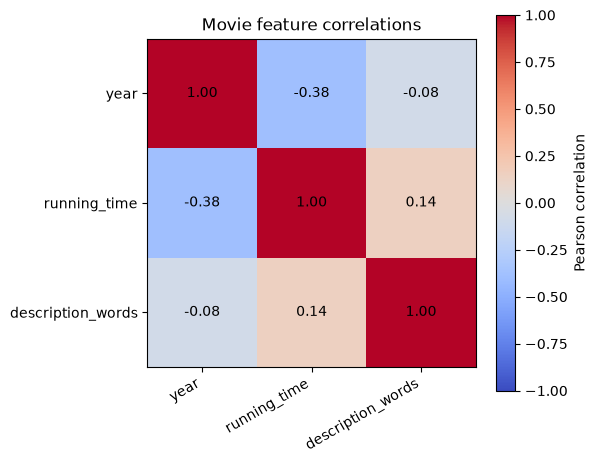

In [10]:
corr = movies[numeric_features].corr()
display(corr.round(3))
fig, ax = plt.subplots(figsize=(6, 5))
plot = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=30, ha='right')
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center')
fig.colorbar(plot, ax=ax, label='Pearson correlation')
ax.set_title('Movie feature correlations')
plt.tight_layout()
plt.show()

### 8.6 User-Rating and Interaction Analysis

**Studying MovieLens preferences.** Rating frequency shows which scores are common. Interaction counts reveal users with few ratings and movies with little feedback. Matrix sparsity is the percentage of possible user–movie pairs with no observed rating. A missing rating is not a dislike.

MovieLens user–catalogue matrix sparsity: 98.30%


,Ratings per user,Ratings per rated movie
count,610.000000,9724.000000
mean,165.304918,10.369807
std,269.480584,22.401005
min,20.000000,1.000000
25%,35.000000,1.000000
50%,70.500000,3.000000
75%,168.000000,9.000000
max,2698.000000,329.000000


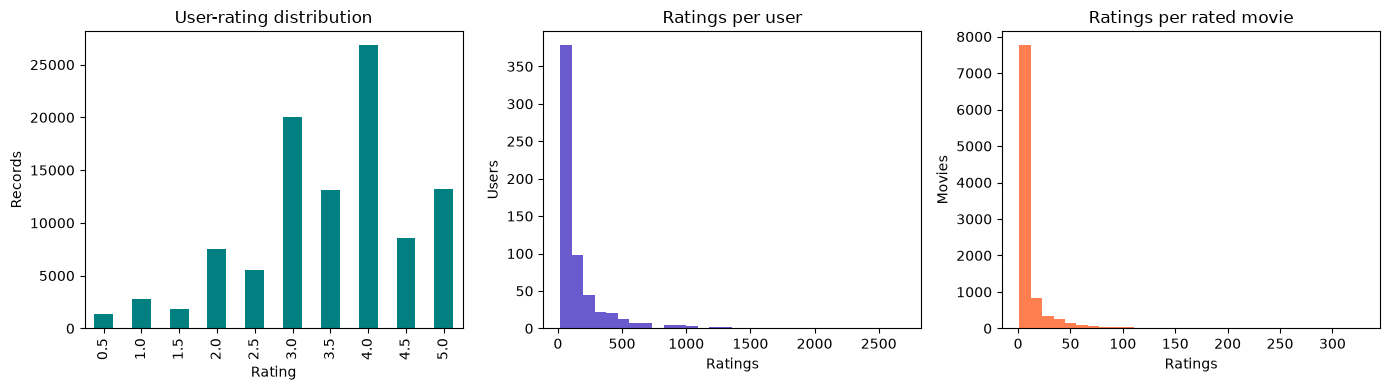

In [11]:
user_counts = ratings.groupby('userId').size()
item_counts = ratings.groupby('movieId').size()
pairs = ratings[['userId', 'movieId']].drop_duplicates()
sparsity = 100 * (1 - len(pairs) / (ratings.userId.nunique() * ml_movies.movieId.nunique()))
print(f'MovieLens user–catalogue matrix sparsity: {sparsity:.2f}%')
display(pd.DataFrame({'Ratings per user': user_counts.describe(),
                      'Ratings per rated movie': item_counts.describe()}))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ratings.rating.value_counts().sort_index().plot.bar(ax=axes[0], color='teal')
axes[0].set(title='User-rating distribution', xlabel='Rating', ylabel='Records')
user_counts.plot.hist(bins=30, ax=axes[1], color='slateblue')
axes[1].set(title='Ratings per user', xlabel='Ratings', ylabel='Users')
item_counts.plot.hist(bins=30, ax=axes[2], color='coral')
axes[2].set(title='Ratings per rated movie', xlabel='Ratings', ylabel='Movies')
plt.tight_layout()
plt.show()

### 8.7 Matching Coverage Between Datasets

**Checking which catalogue movies have MovieLens ratings.** Normalize titles and require the same release year. Exclude missing years, empty keys and ambiguous title/year combinations. These are candidate identity matches; inspect the exported audit before relying on them. English-title normalization may miss alternate titles or transliterations.

Candidate movie matches: 304
Catalogue matching coverage: 6.67%
Ratings for matched movies: 8125
Users with matched ratings: 572


,hotstar_id,title_hotstar,title_movielens,year
0,1000103842,Dragon Blade,Dragon Blade (2015),2015
1,1221006195,Spider-Man,Spider-Man (2002),2002
2,1260016408,John Carter,John Carter (2012),2012
3,1260016410,Captain America: The Winter Soldier,Captain America: The Winter Soldier (2014),2014
4,1260016570,Shanghai Knights,Shanghai Knights (2003),2003
5,1260016574,Finding Dory,Finding Dory (2016),2016
6,1260016768,Captain America: Civil War,Captain America: Civil War (2016),2016
7,1260016769,Cars 2,Cars 2 (2011),2011
8,1260016795,Alice In Wonderland,Alice in Wonderland (2010),2010
9,1260016797,Race To Witch Mountain,Race to Witch Mountain (2009),2009


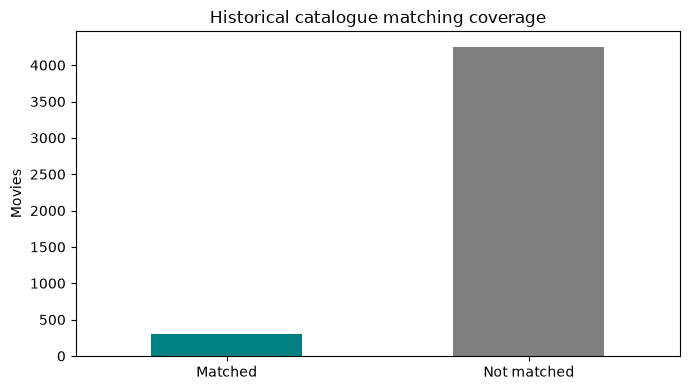

In [12]:
def title_key(title):
    text = re.sub(r'\s*\(\d{4}\)\s*$', '', str(title))
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode().lower()
    text = re.sub(r',\s*(the|a|an)$', r' \1', text)
    return re.sub(r'[^a-z0-9]', '', text)

movies['title_key'] = movies.title.map(title_key)
ml_for_match = ml_movies.copy()
ml_for_match['title_key'] = ml_for_match.title.map(title_key)
ml_for_match['year'] = pd.to_numeric(
    ml_for_match.title.str.extract(r'\((\d{4})\)$')[0], errors='coerce')
left = movies.loc[movies.year.notna() & movies.title_key.ne('')].copy()
right = ml_for_match.loc[ml_for_match.year.notna() & ml_for_match.title_key.ne('')].copy()
left = left.loc[~left.duplicated(['title_key', 'year'], keep=False)]
right = right.loc[~right.duplicated(['title_key', 'year'], keep=False)]
matches = left[['hotstar_id', 'title', 'title_key', 'year']].merge(
    right[['movieId', 'title', 'title_key', 'year']],
    on=['title_key', 'year'], suffixes=('_hotstar', '_movielens'), validate='one_to_one')
matched_ratings = ratings.merge(matches[['movieId', 'hotstar_id']], on='movieId', validate='many_to_one')
coverage = len(matches) / len(movies) * 100
print('Candidate movie matches:', len(matches))
print(f'Catalogue matching coverage: {coverage:.2f}%')
print('Ratings for matched movies:', len(matched_ratings))
print('Users with matched ratings:', matched_ratings.userId.nunique())
display(matches[['hotstar_id', 'title_hotstar', 'title_movielens', 'year']].head(15))
fig, ax = plt.subplots(figsize=(7, 4))
pd.Series({'Matched': len(matches), 'Not matched': len(movies) - len(matches)}).plot.bar(ax=ax, color=['teal', 'gray'])
ax.set(title='Historical catalogue matching coverage', ylabel='Movies')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
matches.to_csv(OUTPUT / 'title_matches_for_review.csv', index=False)

## 9. Recommendation Target and Input Features

This is a **personalized ranking task**. The final output will be a list of movies ordered by their estimated relevance to a user.

| Component | Inputs | Output / learning signal |
|---|---|---|
| Content recommendation | Movie descriptions, genres and favourite movies | Similarity-based movie ranking; no class label required |
| Collaborative recommendation | Training user–movie interactions | Ranking based on users with similar preferences |
| Optional supervised rankers | Content vectors, user profiles and training-only interaction statistics | Predicted MovieLens rating, used to rank unseen movies |

`rating` is an observed preference signal. A held-out rating of **4 or above** will be treated as relevant for top-10 evaluation. Age rating is not the prediction target. IDs link records; they should not be used as continuous measurements. `seasons` and `episodes` are excluded from movie features.

## 10. Proposed Data Preprocessing Pipeline

The following steps will be implemented for modelling in the final phase:

| Step | Planned treatment | Reason |
|---|---|---|
| Movie selection | Keep movie records and valid IDs/titles | Define the recommendation catalogue |
| Missing values | Empty text for missing descriptions; explicit unknown genre; training-set median only if numeric model features need it | Avoid dropping useful movies unnecessarily |
| Duplicate handling | Investigate repeated IDs and user/movie pairs; retain distinct remakes | Avoid accidental duplication or merging different movies |
| Text features | TF-IDF for descriptions and genres | Convert text into numerical features |
| Rating linkage | Audit normalized-title/year candidate matches | Avoid attaching ratings to the wrong movie |
| Train/test split | Seeded per-user 80:20 holdout for users with at least five matched ratings | Keep training history for evaluated users |
| Leakage control | Build user profiles, similarities, popularity and rating aggregates from training interactions only | Prevent test ratings influencing recommendations |
| Validation | Use a separate validation split inside training for tuning; keep test ratings untouched | Compare models fairly |
| Cold start | Content-based suggestions from selected favourites; popularity fallback if no preferences | Serve users/items with limited interactions |

The random holdout evaluates known users; it does not demonstrate future-time prediction or performance for completely new users. Public movie metadata may be used as a fixed catalogue, while all user-dependent features must be learned from training data.

## 11. Shortlisted Machine Learning Approaches

Six approaches are proposed for the final phase. A weighted-popularity baseline will also be reported.

| No. | Approach | Type | Role |
|---|---|---|---|
| 1 | TF-IDF and cosine similarity | Content-based | Recommend movies with similar descriptions and genres |
| 2 | User-neighbour collaborative filtering | Neighbourhood-based | Use the preferences of similar users |
| 3 | Truncated SVD on a sparse interaction matrix | Latent-factor baseline | Explore compact user/movie preference patterns |
| 4 | Random Forest Regressor | Ensemble — bagging | Predict ratings using user-profile and movie features |
| 5 | Gradient Boosting Regressor | Ensemble — boosting | Explore nonlinear rating prediction with compact features |
| 6 | Weighted hybrid recommender | Score-level combination | Combine content and collaborative scores with a popularity fallback |

For the two regressors, construct features for each user–movie pair from movie metadata, the user's **other training ratings**, and training-only aggregates. Exclude the target pair's rating from its feature construction; use cross-fitting where aggregates could otherwise leak it. Use reduced text dimensions for computational efficiency. Predicted ratings become ranking scores.

These approaches motivate Phase 2, which also compares Ridge, KNN, Decision Tree and SVR regressors. No models are trained in Phase 1. Model comparison will determine whether a hybrid improves recommendation quality.


## 12. Proposed Evaluation and Expected Outcome

**Final evaluation:** Compare models using the same held-out users and candidate movies. Exclude movies already rated in the user's training history. Report results on the matched, training-observed catalogue and report how much of the full catalogue this covers.

- **Precision@10:** How many of the ten suggestions are relevant held-out movies?
- **Recall@10:** How many relevant held-out movies appear in the ten suggestions?
- **NDCG@10:** Are relevant movies placed near the top?
- **Catalogue coverage:** How many different eligible movies are recommended across users?
- **RMSE/MAE:** Optional secondary measures for models that predict ratings.

Unobserved items have unknown preferences, so offline top-10 metrics are an incomplete estimate of actual user satisfaction. The small matched subset may favour movies common in MovieLens. Report this limitation rather than claiming results represent every Hotstar movie.

**Expected final output:** A user chooses favourite movies and receives a ranked list, movie details and simple recommendation reasons. Genre, release-year and runtime filters can be included. Current streaming availability will not be claimed without a verified availability source.

## 13. Phase 1 Findings and Deliverables

**Generating the findings from the supplied data.** These are dataset observations, not model-performance results.

In [13]:
findings = pd.DataFrame([
    ['Historical Hotstar catalogue records', len(hotstar_raw)],
    ['Movie records retained for analysis', len(movies)],
    ['MovieLens movie records', len(ml_movies)],
    ['MovieLens rating records', len(ratings)],
    ['MovieLens users', ratings.userId.nunique()],
    ['Candidate title/year matches', len(matches)],
    ['Matched movie ratings', len(matched_ratings)],
    ['Catalogue matching coverage (%)', round(coverage, 2)],
    ['Movies with empty descriptions', int(movies.description.eq('').sum())],
    ['MovieLens user/catalogue sparsity (%)', round(sparsity, 2)]
], columns=['Observation', 'Value'])
display(findings)
findings.to_csv(OUTPUT / 'phase1_findings.csv', index=False)
assert movies.hotstar_id.is_unique
assert matches.movieId.is_unique and matches.hotstar_id.is_unique
assert ratings.rating.between(0.5, 5).all()
print('Phase 1 complete: dataset analysis and final-phase plan prepared.')
print('No recommendation model has been trained or evaluated in Phase 1.')

,Observation,Value
0,Historical Hotstar catalogue records,6874.00
1,Movie records retained for analysis,4557.00
2,MovieLens movie records,9742.00
3,MovieLens rating records,100836.00
4,MovieLens users,610.00
5,Candidate title/year matches,304.00
6,Matched movie ratings,8125.00
7,Catalogue matching coverage (%),6.67
8,Movies with empty descriptions,0.00
9,MovieLens user/catalogue sparsity (%),98.30


Phase 1 complete: dataset analysis and final-phase plan prepared.
No recommendation model has been trained or evaluated in Phase 1.


### Interpretation

The catalogue provides movie content for a content-based recommender. Only a small subset can be linked to MovieLens, so collaborative recommendation cannot be assumed to cover the whole catalogue. Sparse interactions motivate content-based and popularity fallbacks. Missing TV-specific fields in movie rows do not need imputation.

### Phase-wise Work

| Phase 1 — this notebook | Final project — later submission |
|---|---|
| Problem statement and objectives | Preprocessing and train/validation/test preparation |
| Dataset metadata and quality checks | Model implementation and tuning |
| EDA, outlier and correlation analysis | Fair model comparison and error analysis |
| Candidate matching and coverage audit | Personalized recommendations, filters and explanations |
| Proposed preprocessing, models and evaluation | Demonstration, conclusions and limitations |

## 14. References

1. Historical Hotstar data repository: https://github.com/SumitMakariye/Hotstar-Data-Analysis-Using-Python — original collection date, region and current availability are unverified. Source MIT licence is bundled.
2. GroupLens MovieLens latest-small: https://grouplens.org/datasets/movielens/latest/ — use the included snapshot and README for its conditions.
3. F. Maxwell Harper and Joseph A. Konstan (2015), *The MovieLens Datasets: History and Context*, ACM Transactions on Interactive Intelligent Systems. https://doi.org/10.1145/2827872
